In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download("adityakadiwal/water-potability")

for file in os.listdir(path):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(path, file))
        break

print("Dataset Shape:", df.shape)
print("\nFirst 10 Rows:")
print(df.head(10))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nPotability Class Distribution:")
print(df["Potability"].value_counts())

Using Colab cache for faster access to the 'water-potability' dataset.
Dataset Shape: (3276, 10)

First 10 Rows:
          ph    Hardness        Solids  Chloramines     Sulfate  Conductivity  \
0        NaN  204.890455  20791.318981     7.300212  368.516441    564.308654   
1   3.716080  129.422921  18630.057858     6.635246         NaN    592.885359   
2   8.099124  224.236259  19909.541732     9.275884         NaN    418.606213   
3   8.316766  214.373394  22018.417441     8.059332  356.886136    363.266516   
4   9.092223  181.101509  17978.986339     6.546600  310.135738    398.410813   
5   5.584087  188.313324  28748.687739     7.544869  326.678363    280.467916   
6  10.223862  248.071735  28749.716544     7.513408  393.663396    283.651634   
7   8.635849  203.361523  13672.091764     4.563009  303.309771    474.607645   
8        NaN  118.988579  14285.583854     7.804174  268.646941    389.375566   
9  11.180284  227.231469  25484.508491     9.077200  404.041635    563.885481

In [ ]:
X = df.drop("Potability", axis=1)
y = df["Potability"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

In [ ]:
lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

svc_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(probability=True, random_state=42))
])

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42))
])

In [ ]:
models = {
    "Logistic Regression": lr_pipeline,
    "SVC": svc_pipeline,
    "Random Forest": rf_pipeline
}

results = []

def evaluate_model(name, model):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0)
    })

    return predictions

for name, model in models.items():
    evaluate_model(name, model)

In [ ]:
#%% Voting Classifier - Hard Voting
voting_hard = VotingClassifier(
    estimators=[
        ("lr", lr_pipeline),
        ("svc", svc_pipeline),
        ("rf", rf_pipeline)
    ],
    voting="hard"
)

evaluate_model("Voting Hard", voting_hard)


#%% Voting Classifier - Soft Voting
voting_soft = VotingClassifier(
    estimators=[
        ("lr", lr_pipeline),
        ("svc", svc_pipeline),
        ("rf", rf_pipeline)
    ],
    voting="soft"
)

evaluate_model("Voting Soft", voting_soft)


#%% Single Decision Tree
dt_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=42))
])

evaluate_model("Single Decision Tree", dt_pipeline)


#%% Bagging - 10 Estimators with Bootstrap
bagging_10 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=10,
        max_samples=0.5,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ))
])

evaluate_model("Bagging 10 Bootstrap", bagging_10)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0,

In [ ]:
#%% Bagging - 100 Estimators with Bootstrap
bagging_100 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        max_samples=0.5,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ))
])

evaluate_model("Bagging 100 Bootstrap", bagging_100)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0,

In [ ]:
#%% Pasting - 100 Estimators without Bootstrap
pasting_100 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        max_samples=0.5,
        bootstrap=False,
        random_state=42,
        n_jobs=-1
    ))
])

evaluate_model("Pasting 100", pasting_100)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [ ]:
#%% Compare All Models
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="F1-Score", ascending=False)

print("\nModel Comparison:")
print(results_df.to_string(index=False))



Model Comparison:
                Model  Accuracy  Precision   Recall  F1-Score
 Single Decision Tree  0.596037   0.481328 0.453125  0.466801
          Pasting 100  0.672256   0.645390 0.355469  0.458438
        Random Forest  0.663110   0.644628 0.304688  0.413793
Bagging 100 Bootstrap  0.649390   0.604839 0.292969  0.394737
                  SVC  0.670732   0.704082 0.269531  0.389831
 Bagging 10 Bootstrap  0.638720   0.573643 0.289062  0.384416
          Voting Soft  0.670732   0.722222 0.253906  0.375723
          Voting Hard  0.673780   0.783784 0.226562  0.351515
  Logistic Regression  0.609756   0.000000 0.000000  0.000000



Best Model: Single Decision Tree


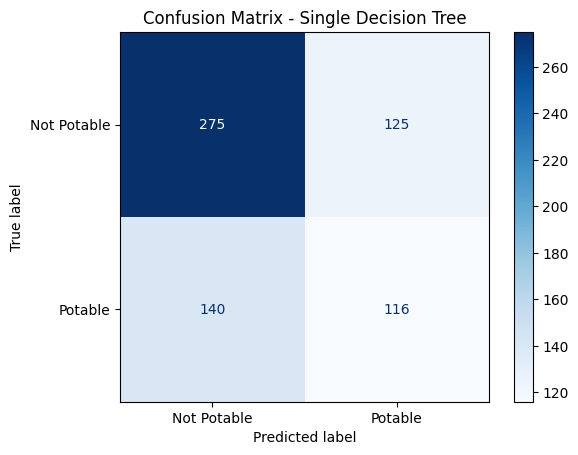

In [ ]:
#%% Confusion Matrix of Best Model
best_model_name = results_df.iloc[0]["Model"]
print("\nBest Model:", best_model_name)

best_models = {
    "Logistic Regression": lr_pipeline,
    "SVC": svc_pipeline,
    "Random Forest": rf_pipeline,
    "Voting Hard": voting_hard,
    "Voting Soft": voting_soft,
    "Single Decision Tree": dt_pipeline,
    "Bagging 10 Bootstrap": bagging_10,
    "Bagging 100 Bootstrap": bagging_100,
    "Pasting 100": pasting_100
}

best_model = best_models[best_model_name]
best_model.fit(X_train, y_train)
best_predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Potable", "Potable"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - " + best_model_name)
plt.show()

In [ ]:
#%% Final Comparison
single_best = results_df[results_df["Model"].isin([
    "Logistic Regression", "SVC", "Random Forest", "Single Decision Tree"
])]["F1-Score"].max()

ensemble_best = results_df[results_df["Model"].isin([
    "Voting Hard", "Voting Soft", "Bagging 10 Bootstrap",
    "Bagging 100 Bootstrap", "Pasting 100"
])]["F1-Score"].max()

print("\nBest Single Model F1-Score:", single_best)
print("Best Ensemble Model F1-Score:", ensemble_best)

if ensemble_best > single_best:
    print("Voting or Bagging performed better than the best single model.")
else:
    print("Voting or Bagging did not beat the best single model.")


Best Single Model F1-Score: 0.46680080482897385
Best Ensemble Model F1-Score: 0.45843828715365237
Voting or Bagging did not beat the best single model.
